In [1]:
# Check missing values after reloading
print("Missing Values:")
print(df.isnull().sum())

# Check dataset dimensions
print("\nDataset Shape:", df.shape)

# Check landing success values
print("\nLanding Class Distribution:")
print(df["Class"].value_counts(dropna=False))

Missing Values:


NameError: name 'df' is not defined

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv("../data/spacex_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (90, 19)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class,Year
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0,2010
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0,2012
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0,2013
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0,2013
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0,2013


In [3]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)

print("\nLanding Class Distribution:")
print(df["Class"].value_counts(dropna=False))

Missing Values:
FlightNumber       0
Date               0
BoosterVersion     0
PayloadMass        0
Orbit              0
LaunchSite         0
Outcome            0
Flights            0
GridFins           0
Reused             0
Legs               0
LandingPad        26
Block              0
ReusedCount        0
Serial             0
Longitude          0
Latitude           0
Class              0
Year               0
dtype: int64

Dataset Shape: (90, 19)

Landing Class Distribution:
Class
1    60
0    30
Name: count, dtype: int64


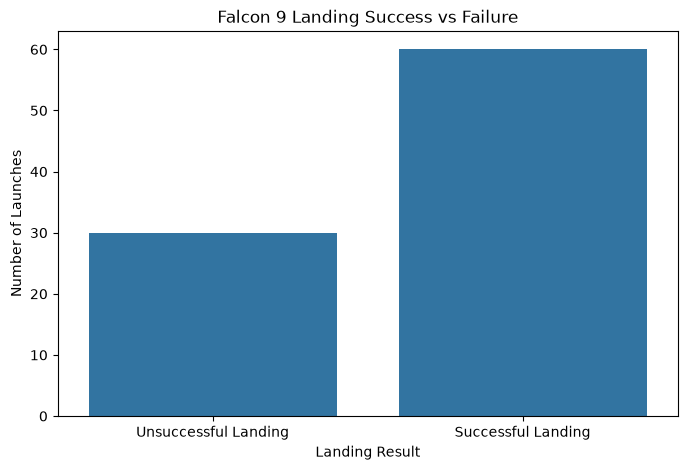

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count successful and unsuccessful landings
landing_counts = df["Class"].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Unsuccessful Landing", "Successful Landing"],
    y=landing_counts.values
)

plt.title("Falcon 9 Landing Success vs Failure")
plt.xlabel("Landing Result")
plt.ylabel("Number of Launches")

plt.show()

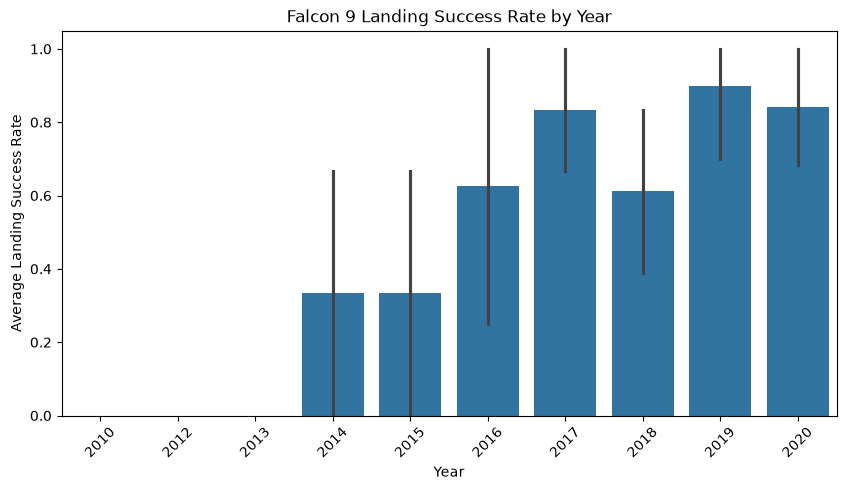

In [5]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x="Year", y="Class")

plt.title("Falcon 9 Landing Success Rate by Year")
plt.xlabel("Year")
plt.ylabel("Average Landing Success Rate")

plt.xticks(rotation=45)
plt.show()

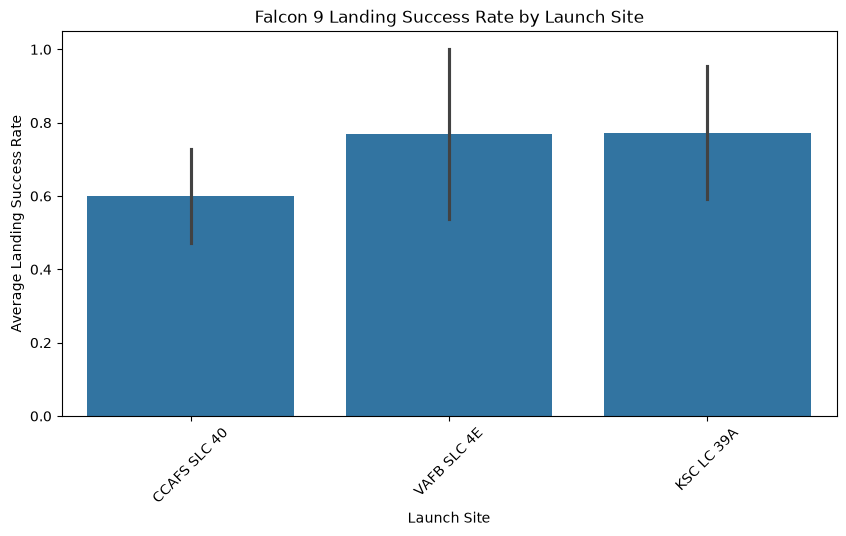

In [6]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x="LaunchSite", y="Class")

plt.title("Falcon 9 Landing Success Rate by Launch Site")
plt.xlabel("Launch Site")
plt.ylabel("Average Landing Success Rate")

plt.xticks(rotation=45)
plt.show()

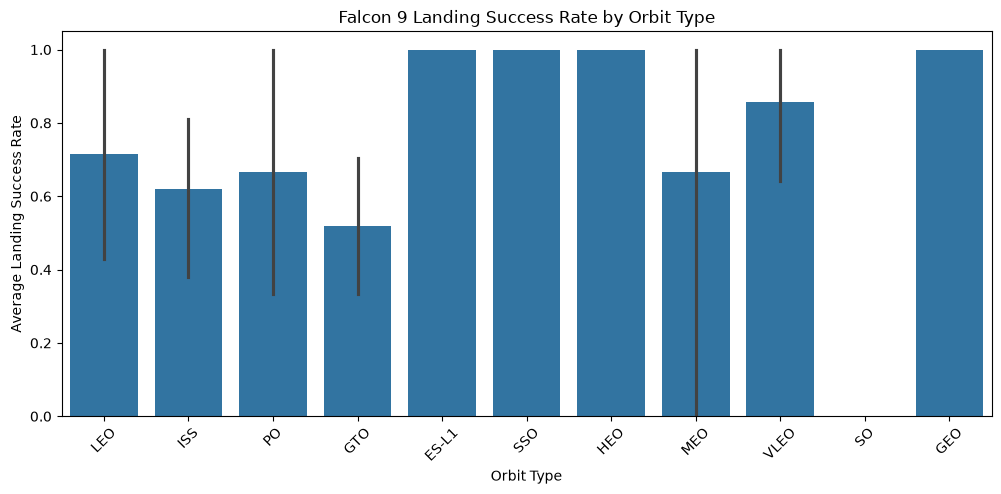

In [7]:
plt.figure(figsize=(12, 5))

sns.barplot(data=df, x="Orbit", y="Class")

plt.title("Falcon 9 Landing Success Rate by Orbit Type")
plt.xlabel("Orbit Type")
plt.ylabel("Average Landing Success Rate")

plt.xticks(rotation=45)
plt.show()

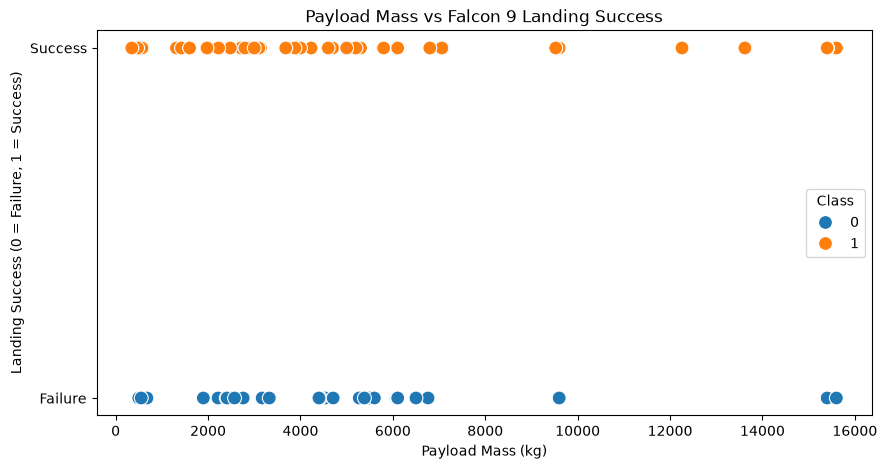

In [8]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="PayloadMass",
    y="Class",
    hue="Class",
    s=100
)

plt.title("Payload Mass vs Falcon 9 Landing Success")
plt.xlabel("Payload Mass (kg)")
plt.ylabel("Landing Success (0 = Failure, 1 = Success)")

plt.yticks([0, 1], ["Failure", "Success"])
plt.show()

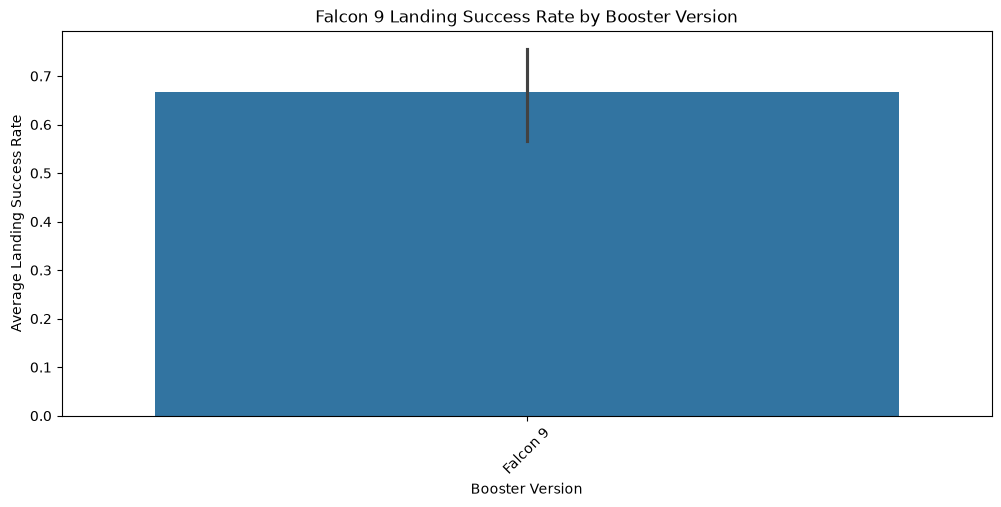

In [9]:
plt.figure(figsize=(12, 5))

sns.barplot(data=df, x="BoosterVersion", y="Class")

plt.title("Falcon 9 Landing Success Rate by Booster Version")
plt.xlabel("Booster Version")
plt.ylabel("Average Landing Success Rate")

plt.xticks(rotation=45)
plt.show()

In [10]:
print("Booster Version Values:")
print(df["BoosterVersion"].value_counts())

Booster Version Values:
BoosterVersion
Falcon 9    90
Name: count, dtype: int64


In [11]:
print("Booster Serial Values:")
print(df["Serial"].value_counts())

Booster Serial Values:
Serial
B1049    6
B1051    5
B1046    4
B1048    4
B1056    4
B1059    4
B1047    3
B1058    3
B1060    3
B1021    2
B1029    2
B1031    2
B1032    2
B1035    2
B1036    2
B1039    2
B1040    2
B1041    2
B1045    2
B0003    1
B0005    1
B0007    1
B1003    1
B1004    1
B1005    1
B1006    1
B1007    1
B1008    1
B1011    1
B1010    1
B1012    1
B1013    1
B1015    1
B1016    1
B1018    1
B1019    1
B1017    1
B1020    1
B1022    1
B1023    1
B1025    1
B1026    1
B1028    1
B1030    1
B1034    1
B1037    1
B1038    1
B1042    1
B1043    1
B1044    1
B1050    1
B1054    1
B1062    1
Name: count, dtype: int64


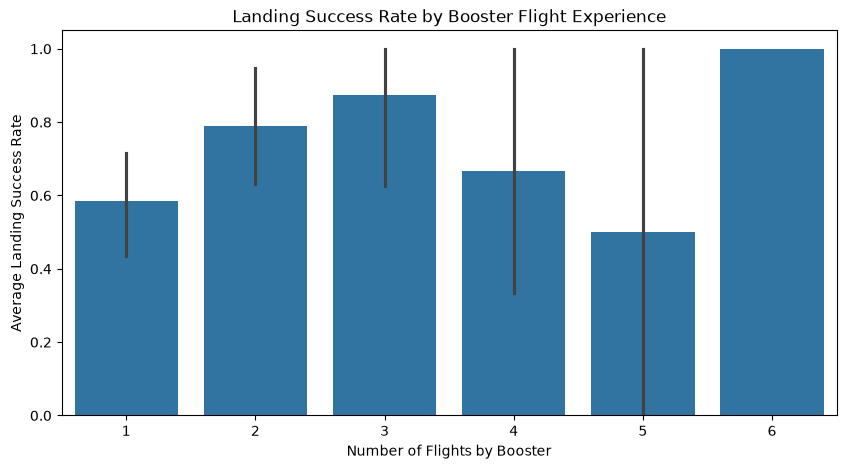

In [12]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x="Flights", y="Class")

plt.title("Landing Success Rate by Booster Flight Experience")
plt.xlabel("Number of Flights by Booster")
plt.ylabel("Average Landing Success Rate")

plt.show()

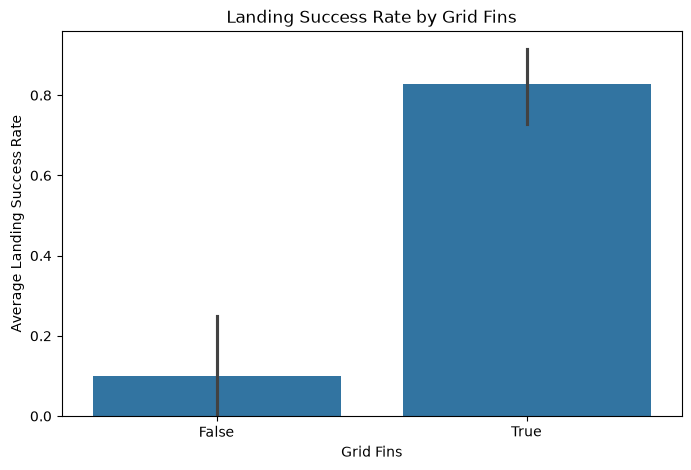

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="GridFins", y="Class")

plt.title("Landing Success Rate by Grid Fins")
plt.xlabel("Grid Fins")
plt.ylabel("Average Landing Success Rate")

plt.show()

In [14]:
gridfins_analysis = df.groupby("GridFins")["Class"].agg(
    Total_Launches="count",
    Successful_Landings="sum",
    Success_Rate="mean"
)

gridfins_analysis["Success_Rate"] *= 100

print(gridfins_analysis)

          Total_Launches  Successful_Landings  Success_Rate
GridFins                                                   
False                 20                    2     10.000000
True                  70                   58     82.857143


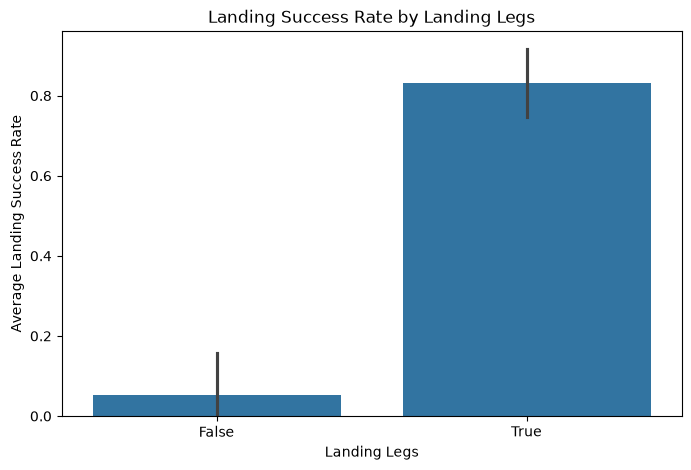

In [15]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="Legs", y="Class")

plt.title("Landing Success Rate by Landing Legs")
plt.xlabel("Landing Legs")
plt.ylabel("Average Landing Success Rate")

plt.show()

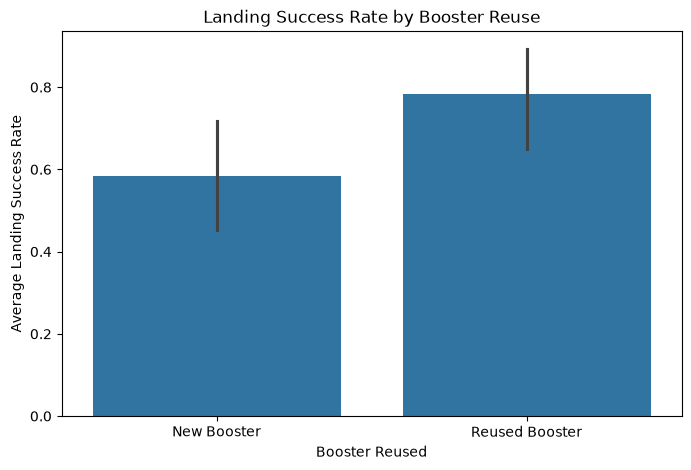

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="Reused", y="Class")

plt.title("Landing Success Rate by Booster Reuse")
plt.xlabel("Booster Reused")
plt.ylabel("Average Landing Success Rate")

plt.xticks([0, 1], ["New Booster", "Reused Booster"])

plt.show()

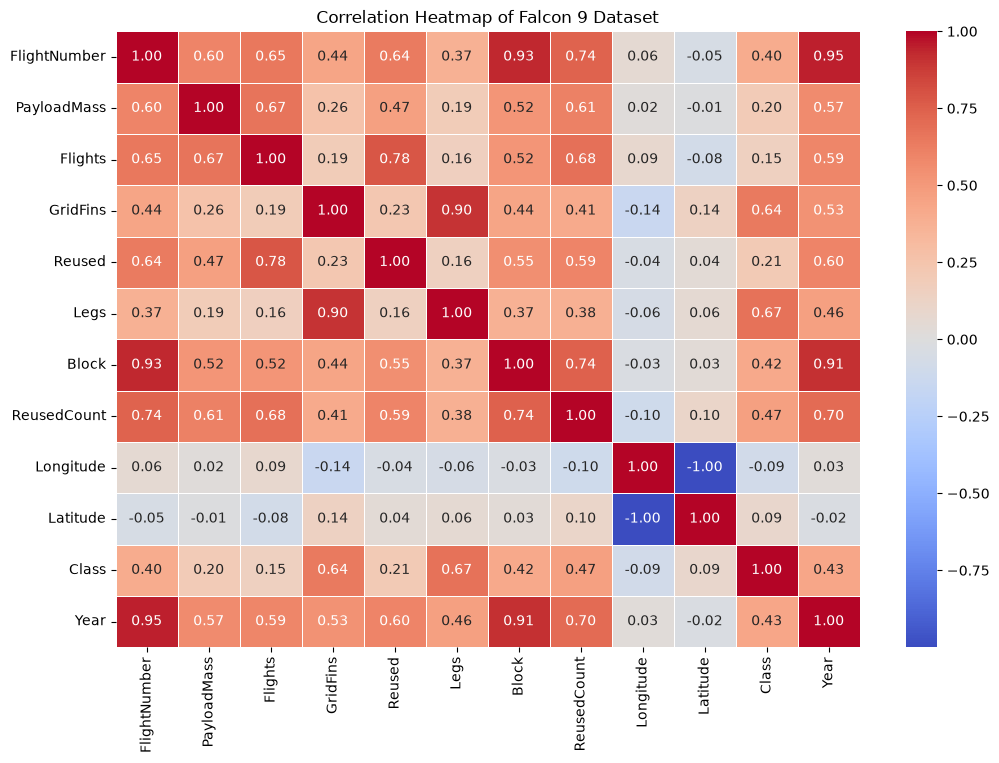

In [17]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=["number", "bool"])

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Falcon 9 Dataset")
plt.show()